# UNSW-NB15 — Arbre_decision (version optimisée)

**Méthodologie inchangée** : partitions officielles, même grille d'hyperparamètres, même validation croisée, même SMOTENC lorsqu'il est activé.

**Optimisation** : mise en cache sur disque des étapes de préparation et de SMOTENC répétées pendant GridSearchCV. La première exécution d'un pli reste coûteuse. Le SVM peut encore être très long.


## 1. Bibliothèques et versions

In [1]:
from joblib import Memory
import time, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, imblearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from sklearn.base import clone
import joblib
SEED = 42
print('Python :', platform.python_version())
print('scikit-learn :', sklearn.__version__)
print('imbalanced-learn :', imblearn.__version__)

Python : 3.11.0rc1
scikit-learn : 1.9.1
imbalanced-learn : 0.14.2


## 2. Chargement et vérifications

In [2]:
# Placer les deux CSV dans le même dossier que ce notebook.
TRAIN_CSV = Path('UNSW_NB15_training-set.csv')
TEST_CSV = Path('UNSW_NB15_1.csv')
for fichier in (TRAIN_CSV, TEST_CSV):
    if not fichier.is_file():
        raise FileNotFoundError(f'Fichier introuvable : {fichier.resolve()}')
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
print('Entraînement :', train_df.shape, '| Test :', test_df.shape)
assert train_df.shape == (175341,45), 'Dimensions du training set inattendues'
assert test_df.shape == (82332,45), 'Dimensions du testing set inattendues'
assert train_df.columns.tolist() == test_df.columns.tolist(), 'Colonnes différentes'
print('Classes entraînement :\n', train_df['label'].value_counts().sort_index())
print('Classes test :\n', test_df['label'].value_counts().sort_index())
print('Valeurs manquantes :', train_df.isna().sum().sum(), test_df.isna().sum().sum())

Entraînement : (175341, 45) | Test : (82332, 45)
Classes entraînement :
 label
0     56000
1    119341
Name: count, dtype: int64
Classes test :
 label
0    37000
1    45332
Name: count, dtype: int64
Valeurs manquantes : 0 0


## 3. Variables explicatives et cible

In [3]:
# Aucun train_test_split : partitions officielles distinctes.
excluded = ['id', 'attack_cat', 'label']
feature_cols = [c for c in train_df.columns if c not in excluded]
X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()
y_train = train_df['label'].astype(int)
y_test = test_df['label'].astype(int)
assert set(y_train.unique()) == {0,1} and set(y_test.unique()) == {0,1}
assert not X_train.isna().any().any() and not X_test.isna().any().any(), 'Valeurs manquantes : adapter le pipeline'
cat_cols = ['proto','service','state']
num_cols = [c for c in feature_cols if c not in cat_cols]
print('Variables explicatives :', len(feature_cols))
print('Numériques :', len(num_cols), '| Catégorielles :', cat_cols)
print('Aucun encodage, scaling ni SMOTE avant la validation croisée.')

Variables explicatives : 42
Numériques : 39 | Catégorielles : ['proto', 'service', 'state']
Aucun encodage, scaling ni SMOTE avant la validation croisée.


## 4. Prétraitement et rééchantillonnage dans les plis

In [4]:
# Pipeline sans SMOTE : encodage OneHot + standardisation, ajustés dans chaque pli.
pre_no_smote = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols)
], sparse_threshold=0)

# Pipeline avec SMOTENC : catégories encodées en entiers uniquement pour le rééchantillonnage.
# Après SMOTENC, elles sont réencodées en one-hot pour le classifieur.
pre_smote = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', 'passthrough', num_cols)
], sparse_threshold=0)
cat_idx = list(range(len(cat_cols)))
post_smote = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_idx),
    ('num', StandardScaler(), list(range(len(cat_cols), len(feature_cols))))
], sparse_threshold=0)

# Le rééchantillonnage a lieu uniquement dans les sous-ensembles d'entraînement de chaque pli.
# Le jeu de test officiel reste strictement inchangé.
# Un cache distinct par algorithme et variante, sur disque local.
# Conserver le dossier cache tant que les données et le protocole restent identiques.
CACHE_ROOT = Path(".cache_unsw_cv")
CACHE_ROOT.mkdir(exist_ok=True)

def make_pipeline(use_smote, model):
    if use_smote:
        return Pipeline([
            ('ordinal', clone(pre_smote)),
            ('smote', SMOTENC(categorical_features=cat_idx, random_state=SEED)),
            ('features', clone(post_smote)),
            ('model', clone(model))
        ], memory=Memory(location=str(CACHE_ROOT / ('avec_SMOTE')), verbose=0))
    return Pipeline([
        ('features', clone(pre_no_smote)),
        ('model', clone(model))
    ], memory=Memory(location=str(CACHE_ROOT / ('sans_SMOTE')), verbose=0))

## 5. Paramètres expérimentaux

In [10]:
MODEL_NAME = 'Arbre de décision'
model = DecisionTreeClassifier(random_state=42)
param_grid = {'model__max_depth': [3, 5, 7, 10], 'model__min_samples_split': [10, 20, 50], 'model__min_samples_leaf': [10, 20, 50]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# Pour la comparaison demandée par le professeur : deux variantes si activées.
variants = ['sans_SMOTE']
print('Modèle :', MODEL_NAME)
print('Grille :', param_grid)
print('Nombre de plis :', cv.get_n_splits())
print('Variantes :', variants)

Modèle : Arbre de décision
Grille : {'model__max_depth': [3, 5, 7, 10], 'model__min_samples_split': [10, 20, 50], 'model__min_samples_leaf': [10, 20, 50]}
Nombre de plis : 5
Variantes : ['sans_SMOTE']


## 6. Recherche et évaluation

La mise en cache évite de répéter certaines étapes identiques dans les plis de validation. La première exécution de chaque pli peut rester longue ; les modèles eux-mêmes sont toujours ajustés pour chaque combinaison. Ne pas supprimer le cache pendant l'entraînement. `n_jobs=1` limite les risques de saturation de la RAM.


In [11]:
results = []
models_fitted = {}
predictions = {}
for variant in variants:
    use_smote = variant == 'avec_SMOTE'
    print(f'\n--- {MODEL_NAME} | {variant} ---', flush=True)
    print('Cache de prétraitement actif :', CACHE_ROOT.resolve(), flush=True)
    pipe = make_pipeline(use_smote, model)
    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv,
        scoring='f1',
        refit=True,
        n_jobs=1,
        verbose=1,
        error_score='raise'
    )
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    best = search.best_estimator_
    y_pred = best.predict(X_test)
    # AUC calculée à partir de scores continus, jamais des étiquettes binaires.
    if hasattr(best, 'predict_proba'):
        scores = best.predict_proba(X_test)[:, 1]
    else:
        scores = best.decision_function(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    row = {
        'modele': MODEL_NAME, 'variante': variant,
        'n_train': len(X_train), 'n_test': len(X_test),
        'cv_folds': cv.get_n_splits(),
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'auc_roc': roc_auc_score(y_test, scores),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'cv_best_f1': search.best_score_,
        'temps_optimisation_et_refit_s': elapsed,
        'meilleurs_parametres': json.dumps(search.best_params_, ensure_ascii=False),
        'seed': SEED
    }
    results.append(row)
    models_fitted[variant] = best
    predictions[variant] = {'y_pred': y_pred, 'scores': scores, 'cm': cm}
    print(pd.Series(row).to_string())
    print('\nRapport de classification :\n', classification_report(y_test, y_pred, digits=4))
results_df = pd.DataFrame(results)
display(results_df)


--- Arbre de décision | sans_SMOTE ---
Cache de prétraitement actif : C:\Users\elieshindano\Desktop\Entrainement des modèles ML\.cache_unsw_cv
Fitting 5 folds for each of 36 candidates, totalling 180 fits
modele                                                           Arbre de décision
variante                                                                sans_SMOTE
n_train                                                                     175341
n_test                                                                       82332
cv_folds                                                                         5
accuracy                                                                  0.844143
precision                                                                 0.786879
recall                                                                    0.983235
f1                                                                        0.874166
auc_roc                                        

,modele,variante,n_train,n_test,cv_folds,accuracy,precision,recall,f1,auc_roc,TN,FP,FN,TP,cv_best_f1,temps_optimisation_et_refit_s,meilleurs_parametres,seed
0,Arbre de décision,sans_SMOTE,175341,82332,5,0.844143,0.786879,0.983235,0.874166,0.973277,24928,12072,760,44572,0.960102,741.977132,"{""model__max_depth"": 10, ""model__min_samples_l...",42


## 7. Matrices de confusion et courbes ROC

FP = trafic normal signalé comme attaque ; FN = attaque non détectée.

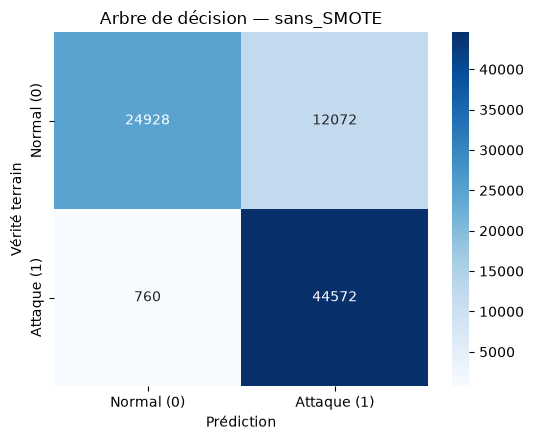

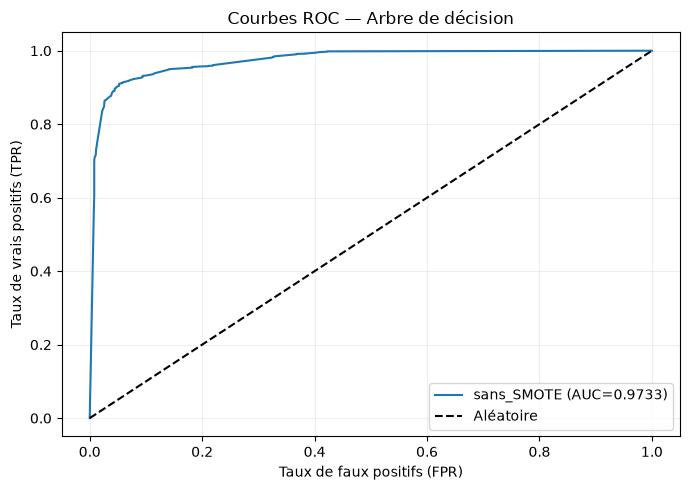

In [12]:
for variant, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5.5,4.5))
    sns.heatmap(pred['cm'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal (0)', 'Attaque (1)'],
                yticklabels=['Normal (0)', 'Attaque (1)'], ax=ax)
    ax.set_xlabel('Prédiction')
    ax.set_ylabel('Vérité terrain')
    ax.set_title(f'{MODEL_NAME} — {variant}')
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(7,5))
for variant, pred in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, pred['scores'])
    area = roc_auc_score(y_test, pred['scores'])
    plt.plot(fpr, tpr, label=f'{variant} (AUC={area:.4f})')
plt.plot([0,1],[0,1],'k--',label='Aléatoire')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.title(f'Courbes ROC — {MODEL_NAME}')
plt.legend()
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 8. Export des résultats et traçabilité

In [8]:
output_dir = Path('resultats_officiels')
output_dir.mkdir(exist_ok=True)
slug = {'Régression logistique':'LR', 'Arbre de décision':'DT',
        'Forêt aléatoire':'RF', 'SVM (RBF)':'SVM'}[MODEL_NAME]
results_df.to_csv(output_dir / f'{slug}_resultats.csv', index=False, encoding='utf-8-sig')
meta = {
    'modele': MODEL_NAME,
    'training_file': TRAIN_CSV.name,
    'testing_file': TEST_CSV.name,
    'python': platform.python_version(),
    'sklearn': sklearn.__version__,
    'imblearn': imblearn.__version__,
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'grille': param_grid,
    'cv_folds': cv.get_n_splits(),
    'cv_shuffle': True,
    'random_state': SEED,
    'machine': platform.platform(),
    'processor': platform.processor()
}
with open(output_dir / f'{slug}_environnement.json','w',encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print('Fichiers enregistrés dans :', output_dir.resolve())
print('Résultats :', output_dir / f'{slug}_resultats.csv')

Fichiers enregistrés dans : C:\Users\elieshindano\Desktop\Entrainement des modèles ML\resultats_officiels
Résultats : resultats_officiels\DT_resultats.csv


## 9. Sauvegarde facultative des modèles

Décommenter uniquement si nécessaire : les fichiers `.joblib` peuvent être volumineux.

In [9]:
# for variant, estimator in models_fitted.items():
#     joblib.dump(estimator, output_dir / f'{slug}_{variant}.joblib')